In [1]:
!pip install tensorflow matplotlib seaborn pandas scikit-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    AveragePooling2D, Flatten,
    Dense, Dropout, GlobalAveragePooling2D,
    BatchNormalization, Resizing
)

from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

print("Training Data:", X_train_full.shape)
print("Testing Data:", X_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1944s 11us/step
Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)


In [4]:
from sklearn.model_selection import train_test_split

X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=5000,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


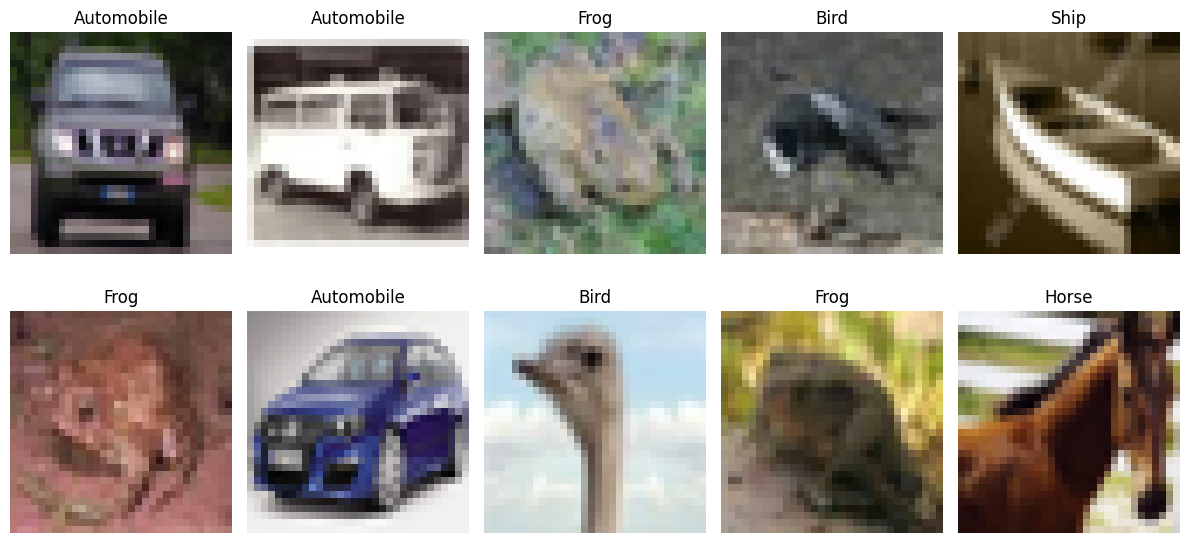

In [5]:
class_names = [
    'Airplane', 'Automobile', 'Bird',
    'Cat', 'Deer', 'Dog',
    'Frog', 'Horse', 'Ship', 'Truck'
]

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])

    plt.title(class_names[y_train[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
def build_lenet():

    model = Sequential([
        Input(shape=(32, 32, 3)),

        Conv2D(6, (5, 5), activation='tanh'),
        AveragePooling2D((2, 2)),

        Conv2D(16, (5, 5), activation='tanh'),
        AveragePooling2D((2, 2)),

        Flatten(),

        Dense(120, activation='tanh'),
        Dense(84, activation='tanh'),

        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [7]:
def build_alexnet():

    model = Sequential([
        Input(shape=(32, 32, 3)),

        Conv2D(64, (3, 3), strides=1,
               padding='same', activation='relu'),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3),
               padding='same', activation='relu'),
        MaxPooling2D((2, 2)),

        Conv2D(256, (3, 3),
               padding='same', activation='relu'),

        Conv2D(256, (3, 3),
               padding='same', activation='relu'),

        Conv2D(128, (3, 3),
               padding='same', activation='relu'),
        MaxPooling2D((2, 2)),

        Flatten(),

        Dense(256, activation='relu'),
        Dropout(0.5),

        Dense(128, activation='relu'),
        Dropout(0.5),

        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [8]:
def build_vgg16_scratch():

    model = Sequential([
        Input(shape=(32, 32, 3)),

        # Block 1
        Conv2D(64, 3, padding='same', activation='relu'),
        Conv2D(64, 3, padding='same', activation='relu'),
        MaxPooling2D(2),

        # Block 2
        Conv2D(128, 3, padding='same', activation='relu'),
        Conv2D(128, 3, padding='same', activation='relu'),
        MaxPooling2D(2),

        # Block 3
        Conv2D(256, 3, padding='same', activation='relu'),
        Conv2D(256, 3, padding='same', activation='relu'),
        Conv2D(256, 3, padding='same', activation='relu'),
        MaxPooling2D(2),

        # Block 4
        Conv2D(512, 3, padding='same', activation='relu'),
        Conv2D(512, 3, padding='same', activation='relu'),
        Conv2D(512, 3, padding='same', activation='relu'),
        MaxPooling2D(2),

        # Block 5
        Conv2D(512, 3, padding='same', activation='relu'),
        Conv2D(512, 3, padding='same', activation='relu'),
        Conv2D(512, 3, padding='same', activation='relu'),
        MaxPooling2D(2),

        GlobalAveragePooling2D(),

        Dense(256, activation='relu'),
        Dropout(0.5),

        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [9]:
def build_resnet50_scratch():

    base_model = ResNet50(
        weights=None,
        include_top=False,
        input_shape=(32, 32, 3)
    )

    inputs = Input(shape=(32, 32, 3))

    x = base_model(inputs)
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)

    outputs = Dense(10, activation='softmax')(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [10]:
models = {
    "LeNet": build_lenet(),
    "AlexNet": build_alexnet(),
    "VGG16": build_vgg16_scratch(),
    "ResNet50": build_resnet50_scratch()
}

for name, model in models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    model.summary()


LeNet


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

... (14 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 1, 1, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 24,061,706 (91.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [11]:
histories = {}
training_times = {}
results = {}

for name, model in models.items():

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    elapsed_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    histories[name] = history
    training_times[name] = elapsed_time

    results[name] = {
        "Training Accuracy": history.history['accuracy'][-1] * 100,
        "Validation Accuracy": history.history['val_accuracy'][-1] * 100,
        "Test Accuracy": test_accuracy * 100,
        "Training Loss": history.history['loss'][-1],
        "Test Loss": test_loss,
        "Training Time": elapsed_time,
        "Parameters": model.count_params()
    }

    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Training Time:", round(elapsed_time, 2), "seconds")


Training: LeNet
Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.3465 - loss: 1.8457 - val_accuracy: 0.3896 - val_loss: 1.7596
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4056 - loss: 1.6947 - val_accuracy: 0.4210 - val_loss: 1.6474
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4402 - loss: 1.5897 - val_accuracy: 0.4528 - val_loss: 1.5482
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4711 - loss: 1.4921 - val_accuracy: 0.4740 - val_loss: 1.4795
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4940 - loss: 1.4207 - val_accuracy: 0.4922 - val_loss: 1.4381
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5152 - loss: 1.3649 - val_accuracy: 0.5042 - val_loss: 1.4126
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5320 - loss: 1.3176 - val_accuracy: 0.5102 - val_loss: 1.3911
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5458 - loss: 1.2762

In [12]:
IMG_SIZE = 96

X_train_res = tf.image.resize(
    X_train, (IMG_SIZE, IMG_SIZE)
)

X_val_res = tf.image.resize(
    X_val, (IMG_SIZE, IMG_SIZE)
)

X_test_res = tf.image.resize(
    X_test, (IMG_SIZE, IMG_SIZE)
)

print("Resized Training:", X_train_res.shape)

Resized Training: (45000, 96, 96, 3)


In [13]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

# Freeze all pretrained layers
base_model.trainable = False

print("Total Layers:", len(base_model.layers))
print("Trainable Layers:", sum(
    layer.trainable for layer in base_model.layers
))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Total Layers: 175
Trainable Layers: 0


In [14]:
inputs = Input(shape=(96, 96, 3))

# ResNet50 preprocessing
x = tf.keras.layers.Lambda(
    lambda image: preprocess_input(image * 255.0)
)(inputs)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dropout(0.5)(x)

outputs = Dense(10, activation='softmax')(x)

resnet_feature_model = Model(inputs, outputs)

resnet_feature_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

resnet_feature_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [15]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def make_resnet_dataset(images, labels, shuffle=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (images, labels)
    )

    if shuffle:
        ds = ds.shuffle(10000, seed=42)

    ds = ds.batch(BATCH_SIZE)

    ds = ds.map(
        lambda x, y: (
            tf.image.resize(x, (96, 96)),
            y
        ),
        num_parallel_calls=AUTOTUNE
    )

    return ds.prefetch(AUTOTUNE)


train_res_ds = make_resnet_dataset(
    X_train, y_train, shuffle=True
)

val_res_ds = make_resnet_dataset(X_val, y_val)

test_res_ds = make_resnet_dataset(X_test, y_test)

In [16]:
start_time = time.time()

feature_history = resnet_feature_model.fit(
    train_res_ds,
    validation_data=val_res_ds,
    epochs=5,
    verbose=1
)

feature_time = time.time() - start_time

feature_test_loss, feature_test_accuracy = (
    resnet_feature_model.evaluate(
        test_res_ds,
        verbose=0
    )
)

print("Feature Extraction Accuracy:",
      round(feature_test_accuracy * 100, 2), "%")

print("Training Time:",
      round(feature_time, 2), "seconds")

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 61s 66ms/step - accuracy: 0.7808 - loss: 0.6749 - val_accuracy: 0.8486 - val_loss: 0.4310
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.8300 - loss: 0.5011 - val_accuracy: 0.8524 - val_loss: 0.4139
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.8452 - loss: 0.4519 - val_accuracy: 0.8616 - val_loss: 0.3926
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 46ms/step - accuracy: 0.8558 - loss: 0.4174 - val_accuracy: 0.8604 - val_loss: 0.3974
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.8632 - loss: 0.3909 - val_accuracy: 0.8690 - val_loss: 0.3874
Feature Extraction Accuracy: 86.27 %
Training Time: 191.6 seconds


In [17]:
base_model.trainable = True

# Freeze all except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

print("Trainable Layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable Layers: 21


In [18]:
resnet_feature_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [19]:
start_time = time.time()

finetune_history = resnet_feature_model.fit(
    train_res_ds,
    validation_data=val_res_ds,
    epochs=5,
    verbose=1
)

finetune_time = time.time() - start_time

finetune_test_loss, finetune_test_accuracy = (
    resnet_feature_model.evaluate(
        test_res_ds,
        verbose=0
    )
)

print("Fine-Tuning Accuracy:",
      round(finetune_test_accuracy * 100, 2), "%")

print("Fine-Tuning Time:",
      round(finetune_time, 2), "seconds")

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 77s 85ms/step - accuracy: 0.8932 - loss: 0.3083 - val_accuracy: 0.8878 - val_loss: 0.3301
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 64ms/step - accuracy: 0.9238 - loss: 0.2170 - val_accuracy: 0.8954 - val_loss: 0.3247
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 44s 63ms/step - accuracy: 0.9433 - loss: 0.1587 - val_accuracy: 0.8994 - val_loss: 0.3366
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 63ms/step - accuracy: 0.9594 - loss: 0.1166 - val_accuracy: 0.9034 - val_loss: 0.3507
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 44s 63ms/step - accuracy: 0.9711 - loss: 0.0819 - val_accuracy: 0.9010 - val_loss: 0.3854
Fine-Tuning Accuracy: 89.63 %
Fine-Tuning Time: 255.27 seconds


In [20]:
results["ResNet50 Feature Extraction"] = {
    "Training Accuracy": feature_history.history['accuracy'][-1] * 100,
    "Validation Accuracy": feature_history.history['val_accuracy'][-1] * 100,
    "Test Accuracy": feature_test_accuracy * 100,
    "Training Loss": feature_history.history['loss'][-1],
    "Test Loss": feature_test_loss,
    "Training Time": feature_time,
    "Parameters": resnet_feature_model.count_params()
}

results["ResNet50 Fine-Tuning"] = {
    "Training Accuracy": finetune_history.history['accuracy'][-1] * 100,
    "Validation Accuracy": finetune_history.history['val_accuracy'][-1] * 100,
    "Test Accuracy": finetune_test_accuracy * 100,
    "Training Loss": finetune_history.history['loss'][-1],
    "Test Loss": finetune_test_loss,
    "Training Time": finetune_time,
    "Parameters": resnet_feature_model.count_params()
}

results_df = pd.DataFrame(results).T

print("\nFINAL MODEL COMPARISON")
print(results_df.round(4))


FINAL MODEL COMPARISON
                             Training Accuracy  Validation Accuracy  \
LeNet                                  57.3400                53.54   
AlexNet                                80.5400                73.04   
VGG16                                   9.8467                10.00   
ResNet50                               56.9911                57.50   
ResNet50 Feature Extraction            86.3178                86.90   
ResNet50 Fine-Tuning                   97.1089                90.10   

                             Test Accuracy  Training Loss  Test Loss  \
LeNet                                52.85         1.2044     1.3458   
AlexNet                              72.45         0.5669     0.8668   
VGG16                                10.00         2.3027     2.3026   
ResNet50                             56.40         1.2596     1.2703   
ResNet50 Feature Extraction          86.27         0.3909     0.4088   
ResNet50 Fine-Tuning                 89.63    

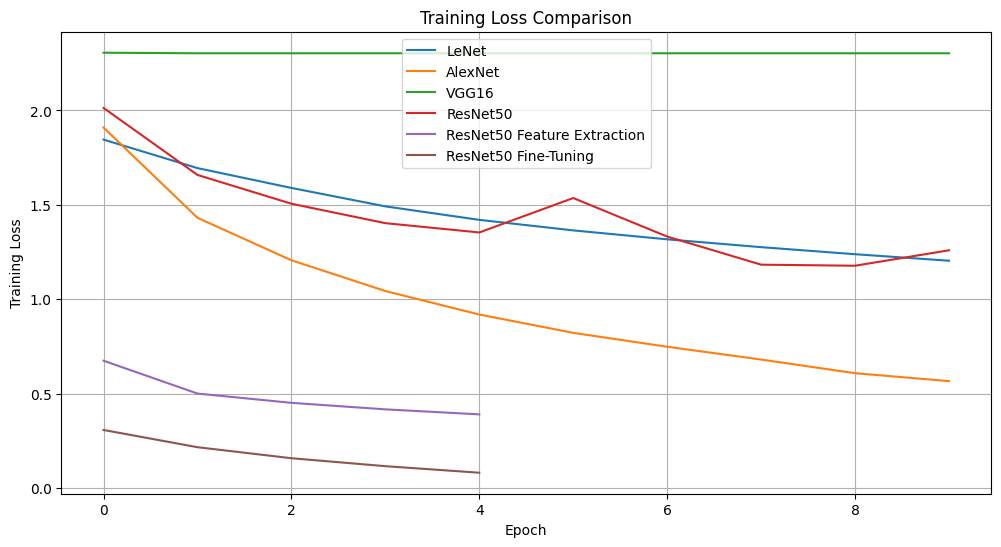

In [21]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history['loss'],
        label=name
    )

plt.plot(
    feature_history.history['loss'],
    label='ResNet50 Feature Extraction'
)

plt.plot(
    finetune_history.history['loss'],
    label='ResNet50 Fine-Tuning'
)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.legend()
plt.grid()
plt.show()

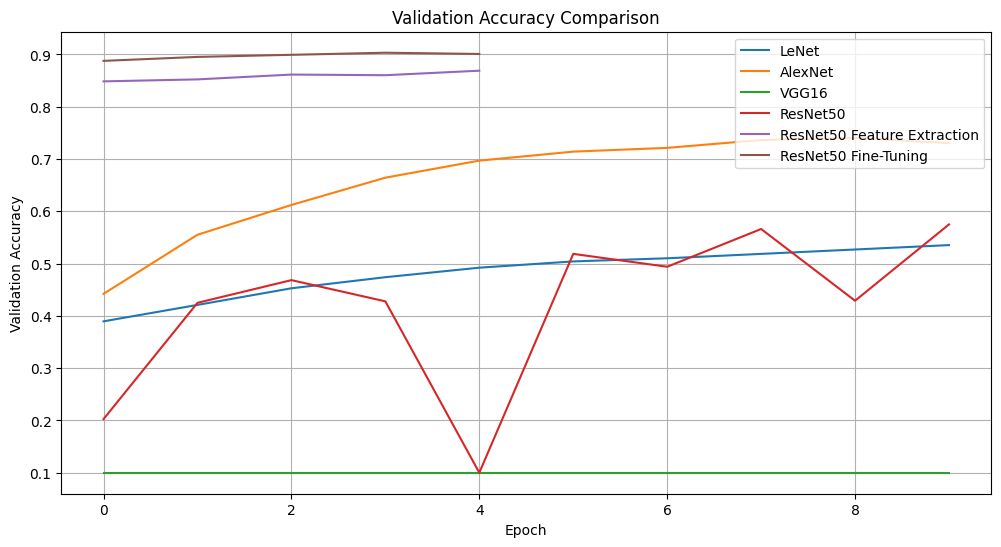

In [22]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history['val_accuracy'],
        label=name
    )

plt.plot(
    feature_history.history['val_accuracy'],
    label='ResNet50 Feature Extraction'
)

plt.plot(
    finetune_history.history['val_accuracy'],
    label='ResNet50 Fine-Tuning'
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid()
plt.show()

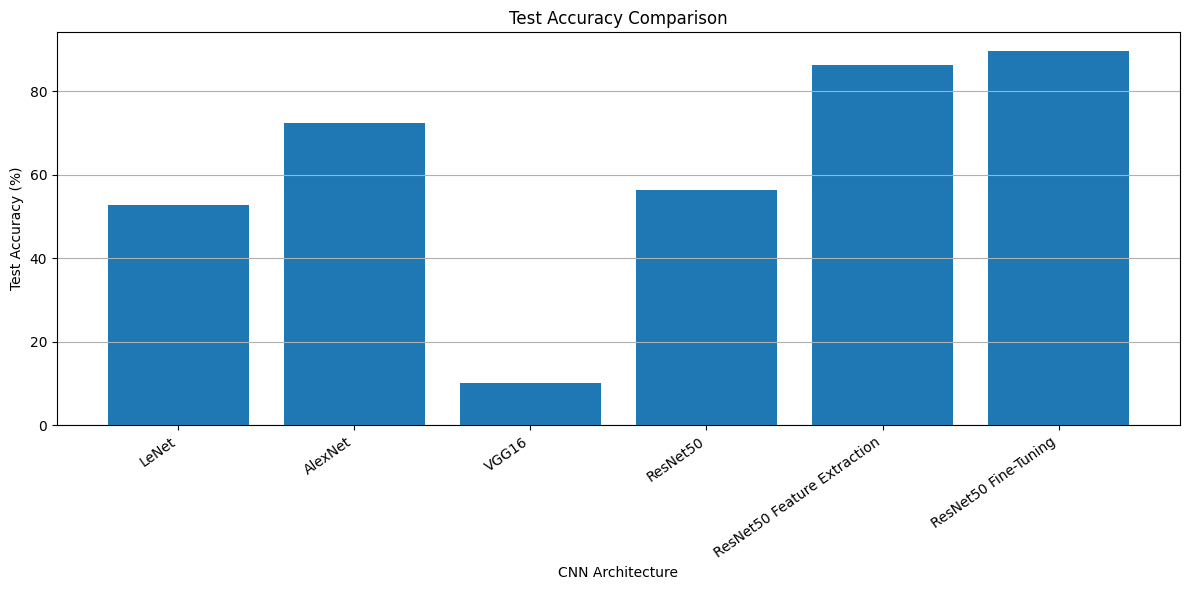

In [23]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df.index,
    results_df['Test Accuracy']
)

plt.title("Test Accuracy Comparison")
plt.xlabel("CNN Architecture")
plt.ylabel("Test Accuracy (%)")

plt.xticks(rotation=35, ha='right')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

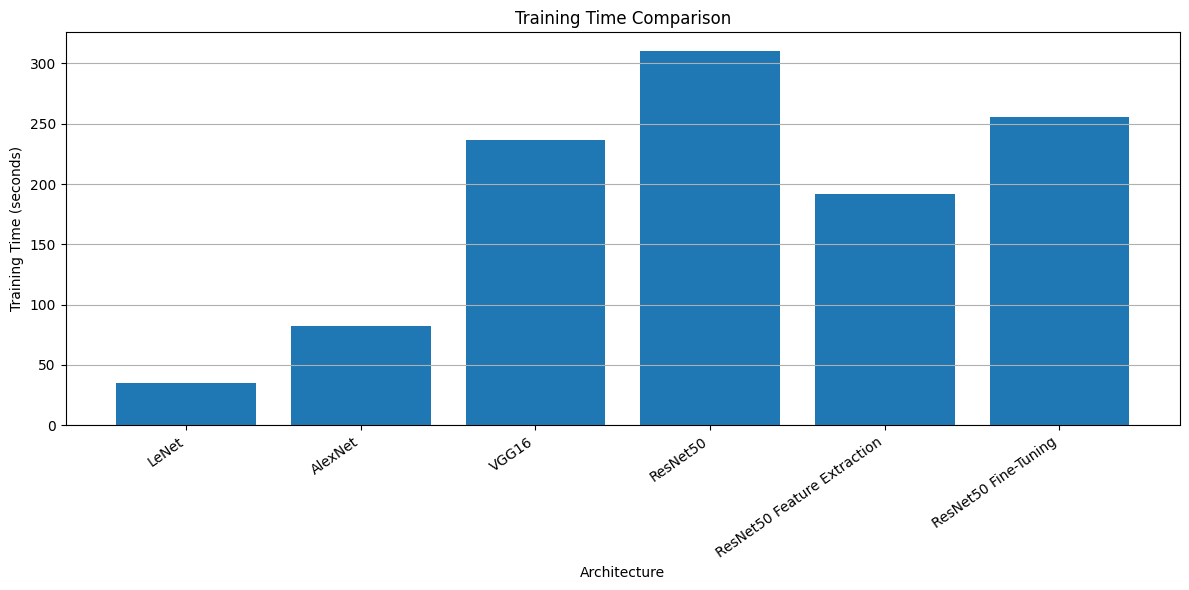

In [24]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df.index,
    results_df['Training Time']
)

plt.title("Training Time Comparison")
plt.xlabel("Architecture")
plt.ylabel("Training Time (seconds)")

plt.xticks(rotation=35, ha='right')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

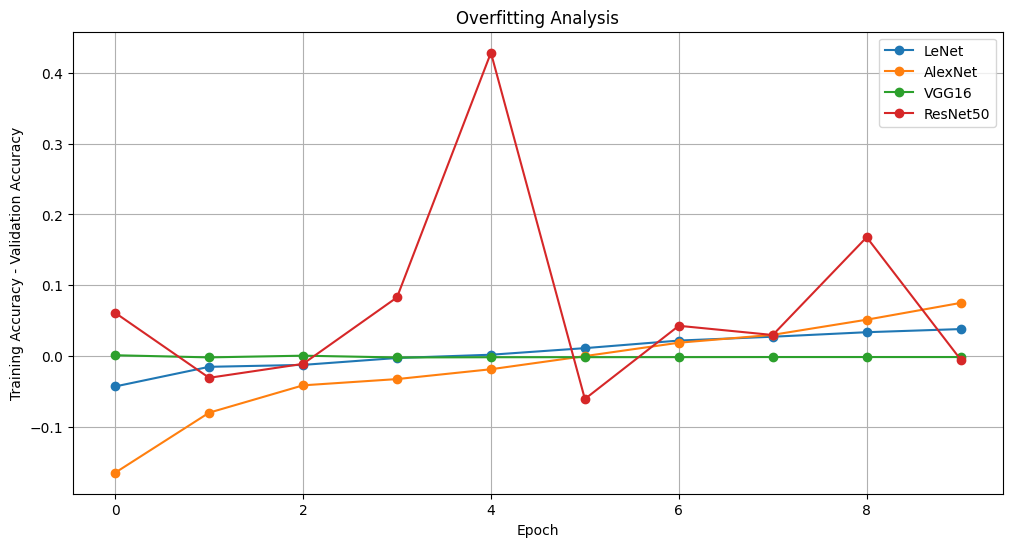

In [25]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    gap = np.array(train_acc) - np.array(val_acc)

    plt.plot(
        gap,
        marker='o',
        label=name
    )

plt.title("Overfitting Analysis")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy - Validation Accuracy")

plt.legend()
plt.grid()
plt.show()

In [26]:
def calculate_gradient_norms(model, X, y):

    X_sample = tf.convert_to_tensor(X[:32])
    y_sample = tf.convert_to_tensor(y[:32])

    with tf.GradientTape() as tape:

        predictions = model(X_sample, training=True)

        loss = tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(
                y_sample,
                predictions
            )
        )

    gradients = tape.gradient(
        loss,
        model.trainable_variables
    )

    results = []

    for layer in model.layers:

        if isinstance(layer, Conv2D):

            for variable, gradient in zip(
                model.trainable_variables,
                gradients
            ):

                if variable is layer.kernel:

                    results.append(
                        float(tf.norm(gradient).numpy())
                    )

                    break

    return results

In [27]:
gradient_results = {}

for name in ["LeNet", "AlexNet", "VGG16"]:

    print("Calculating gradients:", name)

    gradient_results[name] = calculate_gradient_norms(
        models[name],
        X_train,
        y_train
    )

Calculating gradients: LeNet
Calculating gradients: AlexNet
Calculating gradients: VGG16


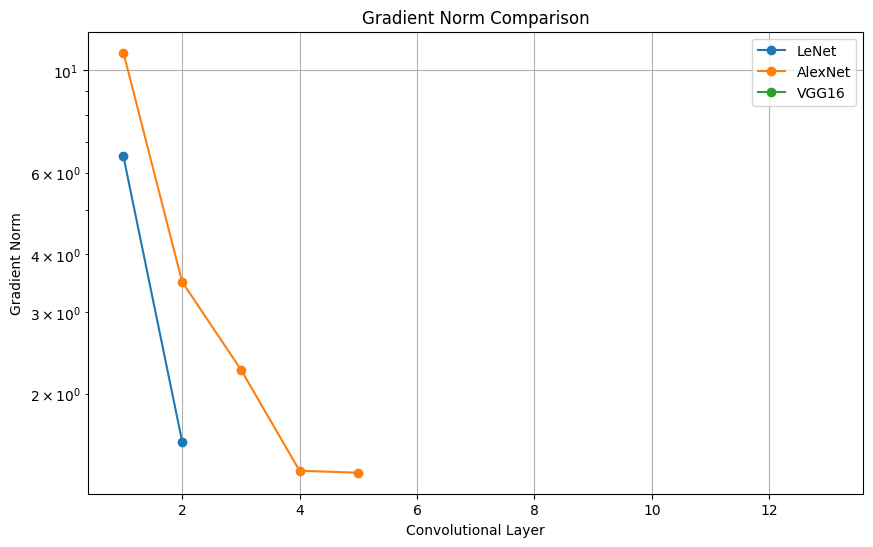

In [28]:
plt.figure(figsize=(10, 6))

for name, norms in gradient_results.items():

    plt.plot(
        range(1, len(norms) + 1),
        norms,
        marker='o',
        label=name
    )

plt.title("Gradient Norm Comparison")
plt.xlabel("Convolutional Layer")
plt.ylabel("Gradient Norm")

plt.yscale('log')
plt.legend()
plt.grid()
plt.show()

In [29]:
print("\nFINAL PERFORMANCE ANALYSIS")

print(
    results_df[
        [
            'Training Accuracy',
            'Validation Accuracy',
            'Test Accuracy',
            'Training Loss',
            'Training Time',
            'Parameters'
        ]
    ].round(3).to_string()
)


FINAL PERFORMANCE ANALYSIS
                             Training Accuracy  Validation Accuracy  Test Accuracy  Training Loss  Training Time  Parameters
LeNet                                   57.340                53.54          52.85          1.204         34.638     62006.0
AlexNet                                 80.540                73.04          72.45          0.567         81.813   1814666.0
VGG16                                    9.847                10.00          10.00          2.303        236.406  14848586.0
ResNet50                                56.991                57.50          56.40          1.260        310.332  24114826.0
ResNet50 Feature Extraction             86.318                86.90          86.27          0.391        191.601  24114826.0
ResNet50 Fine-Tuning                    97.109                90.10          89.63          0.082        255.272  24114826.0


In [30]:
best_model_name = results_df['Test Accuracy'].idxmax()

print("\nBEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model_name)

print(
    "Test Accuracy:",
    round(results_df.loc[best_model_name, 'Test Accuracy'], 2),
    "%"
)


BEST PERFORMING MODEL
---------------------
Model: ResNet50 Fine-Tuning
Test Accuracy: 89.63 %
